# 1. Funnel

In [17]:
import sys; sys.path.append("..")
import pandas as pd
from src.bq import run, save
from src.charts import funnel_chart, rate_heatmap

pd.set_option("display.float_format", "{:,.4f}".format)

In [18]:
overall = run("SELECT * FROM `{project}.{dataset}.funnel_overall` ORDER BY funnel_type, step_order")
users   = run("SELECT * FROM `{project}.{dataset}.funnel_users`")
seg     = run("SELECT * FROM `{project}.{dataset}.funnel_by_segment`")

save(overall, "funnel_overall")
save(users, "funnel_users")
save(seg, "funnel_by_segment")
overall

/Users/brittneychan/ga4-funnel-analysis/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,funnel_type,step_order,step,sessions,pct_of_top,step_conversion,step_dropoff
0,closed,1,view_item,77020,1.0000,NaN,NaN
1,closed,2,add_to_cart,15146,0.1967,0.1967,0.8033
2,closed,3,begin_checkout,5293,0.0687,0.3495,0.6505
3,closed,4,purchase,2751,0.0357,0.5197,0.4803
4,open,1,view_item,77020,1.0000,NaN,NaN
5,open,2,add_to_cart,15188,0.1972,0.1972,0.8028
6,open,3,begin_checkout,11106,0.1442,0.7312,0.2688
7,open,4,purchase,4848,0.0629,0.4365,0.5635


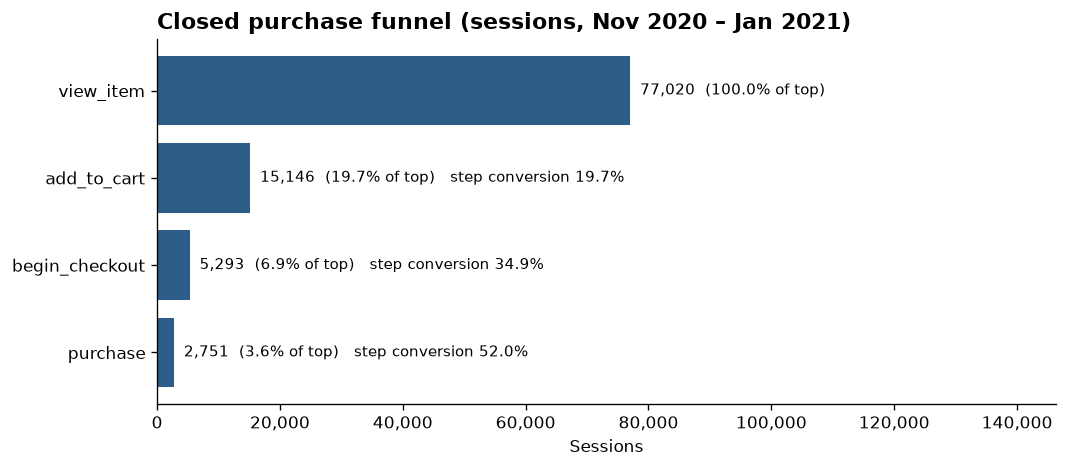

In [19]:
funnel_chart(overall.query("funnel_type == 'closed'"),
    "Closed purchase funnel (sessions, Nov 2020 – Jan 2021)",
    "01_funnel_closed.png");

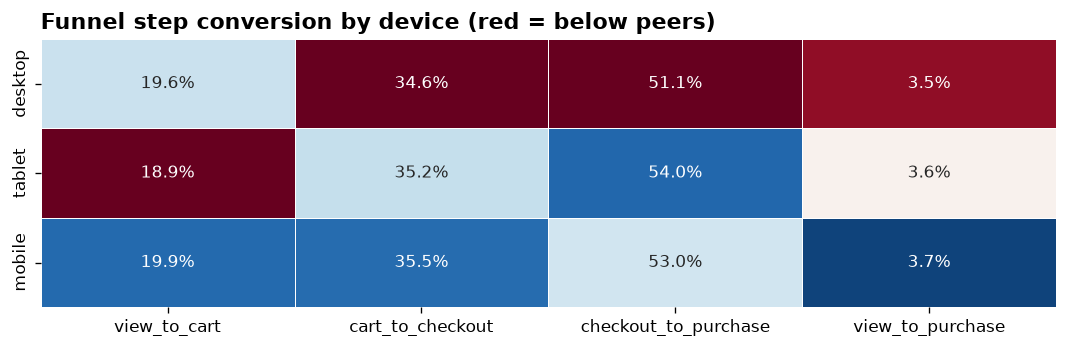

In [20]:
rate_heatmap(seg, "device", "02_heatmap_device.png");

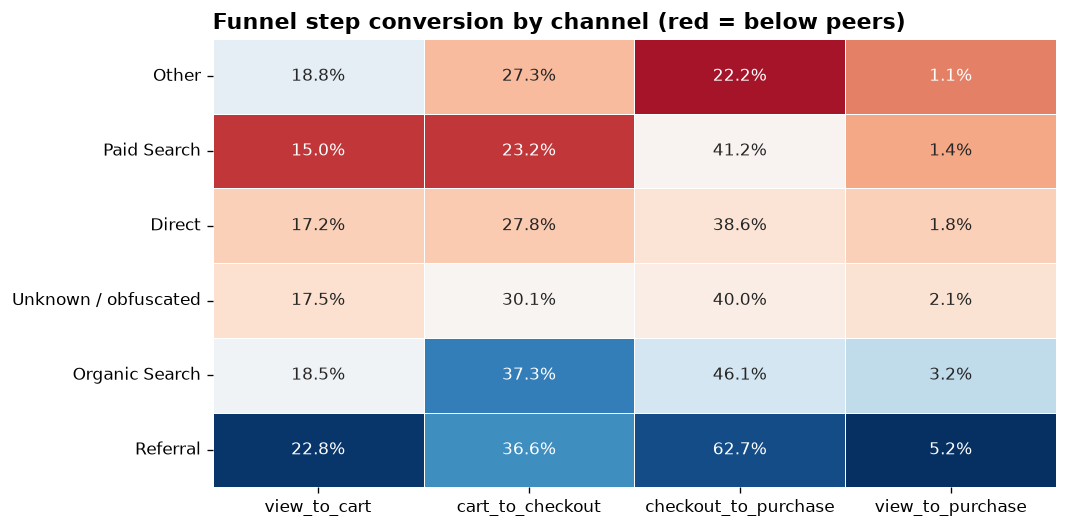

In [21]:
rate_heatmap(seg, "channel", "03_heatmap_channel.png");

In [22]:
# Open vs closed: how many sessions reach steps out of order?
cmp = overall.pivot(index="step", columns="funnel_type", values="sessions")
cmp["pct_out_of_order"] = 1 - cmp["closed"] / cmp["open"]
cmp.loc[["view_item", "add_to_cart", "begin_checkout", "purchase"]]

funnel_type,closed,open,pct_out_of_order
step,,,
view_item,77020,77020,0.0000
add_to_cart,15146,15188,0.0028
begin_checkout,5293,11106,0.5234
purchase,2751,4848,0.4325


In [23]:
# Session-level vs user-level view-to-purchase conversion
opn = overall.query("funnel_type == 'open'").set_index("step")["sessions"]   # open, to match the user-level funnel
session_rate = opn["purchase"] / opn["view_item"]
user_rate = users.loc[0, "user_view_to_purchase"]
print(f"Session-level view→purchase: {session_rate:.2%}")
print(f"User-level view→purchase:    {user_rate:.2%}  ({user_rate / session_rate:.1f}x)")
print(f"Avg sessions, purchasers: {users.loc[0, 'avg_sessions_purchasers']:.1f} "
      f"vs non-purchasers: {users.loc[0, 'avg_sessions_non_purchasers']:.1f}")

Session-level view→purchase: 6.29%
User-level view→purchase:    7.21%  (1.1x)
Avg sessions, purchasers: 3.6 vs non-purchasers: 1.3


### Observations
- Most sessions are lost between view item and add to cart (80.33% drop), and it is the lowest-converting step (19.7%). Later steps convert better: cart to checkout (35%), checkout to purchase (52%). Overall, 3.6% of viewing sessions buy in order. 
- 52% of checkout sessions and 43% of purchase sessions didn't go through earlier steps in the same visit. Open checkouts are 11106 vs 5293 closed. Most likely they added to cart on an earlier visit and came back. 
- Buyers average 3.6 sessions vs 1.3 for non-buyers. Half of checkouts skip earlier steps in that visit.
- It appears tablet users convert worse than desktoop and mobile users from views to cart additions. Desktop users appear to convert worse when moving from cart to checkout and checkout to purchase. Desktop users appear to have the lowest overall product-view-to-purchase conversion rate.
- Paid search traffic appears to convert worse than other channels when moving from view to cart addition and cart to checkout. Other traffic appears to convert worse from checkout to purchas. Other traffic appears to have the lowest overall product-view-to-purchase conversion rate.

# 2. Are the gaps real?

In [24]:
from src.stats import compare_to_baseline, risk_ratio_ci
from src.charts import forest_plot

# Baseline = the reference segment for each dimension
top_channel = seg.query("dimension == 'channel'").nlargest(1, "sessions")["segment"].iloc[0]
results = pd.concat([
    compare_to_baseline(seg, "device", "desktop"),
    compare_to_baseline(seg, "channel", top_channel),
    compare_to_baseline(seg, "visitor_type", "New"),
])
save(results, "segment_tests")
print("Channel baseline:", top_channel)

Channel baseline: Organic Search


In [26]:
# Significant gaps only, worst first
cols = ["dimension", "segment", "step", "rate", "baseline_rate", "abs_diff",
    "diff_ci_low", "diff_ci_high", "p_adj", "cohens_h"]
results.query("significant").sort_values("abs_diff")[cols]

,dimension,segment,step,rate,baseline_rate,abs_diff,diff_ci_low,diff_ci_high,p_adj,cohens_h
8,channel,Paid Search,cart_to_checkout,0.2321,0.3729,-0.1408,-0.1909,-0.0908,0.0000,-0.3085
6,channel,Direct,cart_to_checkout,0.2775,0.3729,-0.0954,-0.1201,-0.0707,0.0000,-0.2042
11,channel,Direct,checkout_to_purchase,0.3862,0.4612,-0.0750,-0.1237,-0.0263,0.0054,-0.1520
7,channel,Unknown / obfuscated,cart_to_checkout,0.3015,0.3729,-0.0714,-0.0981,-0.0448,0.0000,-0.1513
12,channel,Unknown / obfuscated,checkout_to_purchase,0.3996,0.4612,-0.0617,-0.1120,-0.0114,0.0270,-0.1247
3,channel,Paid Search,view_to_cart,0.1502,0.1850,-0.0349,-0.0513,-0.0184,0.0002,-0.0934
18,channel,Paid Search,view_to_purchase,0.0144,0.0318,-0.0175,-0.0231,-0.0118,0.0000,-0.1186
16,channel,Direct,view_to_purchase,0.0184,0.0318,-0.0134,-0.0167,-0.0101,0.0000,-0.0863
1,channel,Direct,view_to_cart,0.1721,0.1850,-0.0130,-0.0216,-0.0043,0.0061,-0.0338
17,channel,Unknown / obfuscated,view_to_purchase,0.0211,0.0318,-0.0107,-0.0144,-0.0070,0.0000,-0.0670


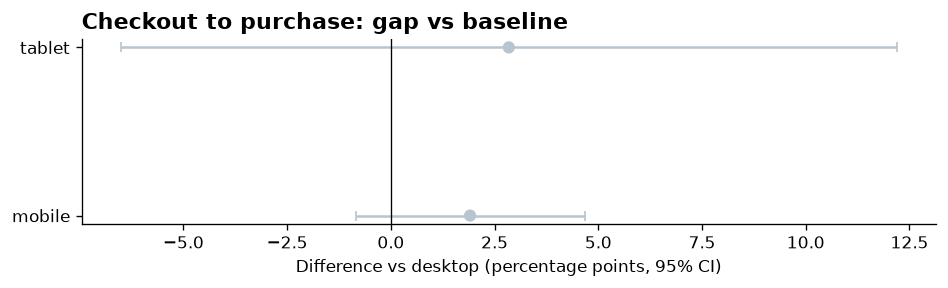

In [27]:
forest_plot(results.query("dimension == 'device'"), "checkout_to_purchase", "04_forest_device_checkout.png");

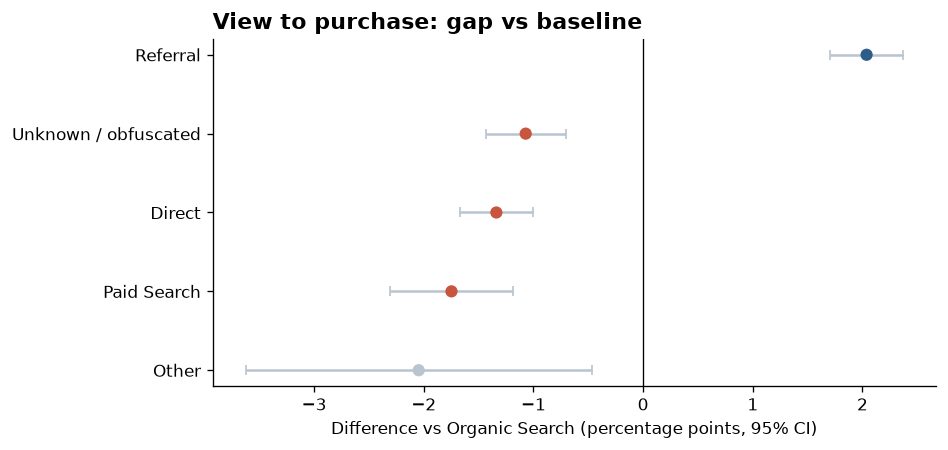

In [28]:
forest_plot(results.query("dimension == 'channel'"), "view_to_purchase", "05_forest_channel.png");

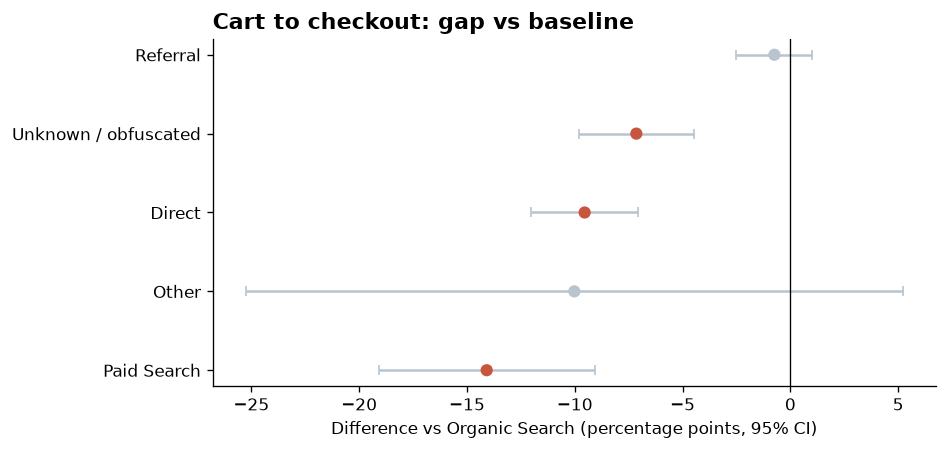

In [30]:
  forest_plot(results.query("dimension == 'channel'"), "cart_to_checkout", "04_forest_channel_cart.png");

In [29]:
# Checkout abandonment: mobile vs desktop, as a ratio with a CI
d = seg.query("dimension == 'device'").set_index("segment")
def abandons(s):
    return d.loc[s, "n_checkout"] - d.loc[s, "n_purchase"], d.loc[s, "n_checkout"]
rr, lo, hi = risk_ratio_ci(*abandons("mobile"), *abandons("desktop"))
print(f"Mobile checkout abandonment is {rr:.2f}x desktop (95% CI {lo:.2f}–{hi:.2f})")

Mobile checkout abandonment is 0.96x desktop (95% CI 0.91–1.02)


### Observations
1. No real difference between devices.
- Mobile checkout abandonment is 0.96x desktop (95% CI 0.91-1.02). Interval includes 1, so can't claim mobile as worse.
- Sample is too small to tell as tablet's whiskers are large.
- Contrary to common assumption, mobile converts as well as desktop at every funn step (checkout abandonment ratio 0.96, 95% CI 0.91–1.02). 
2. Paid search is the weakest channel.
- Cart to checkout: 23.2% vs 37.3% for Organic Search, which is -14.1 pts (95% CI -19.1 to -9.1, BH-adjusted p < 0.001, h = -0.31).
- View to purchase is 1.44% vs 3.18%, so Paid Search converts less than half as well as Organic.
- Direct and Unknown also lag at cart to checkout by -9.5 and -7.1 pts.
- Referral is strongest channel with 62.7% checkout completion vs 46.1%.
3. Returning visitors convert 3x better than new ones.
- View to purchase: 6.7% vs 2.1% 
- Checkout completion: 62.5% vs 41.4% (h = 0.43)
### Limitations
- Sessions from same user aren't fully independent, so p-values slightly optimistic.
- This is observational.
### Recommendations
-  Audit Paid Search: check whether ads match the product pages they lead to, and test the cart page for paid traffic.
- Bring new visitors back, using saved carts and remarketing, since returning visitors convert 3x better.
- Skip a mobile checkout redesign. The data doesn’t support it, and saying so is a valid recommendation.


# 3. What is it worth?

# 4. Takeaways